<a href="https://colab.research.google.com/github/FattahulAlim/Machine_Learning_Sem5/blob/main/JS09/TG9_1_244107020018_MFattahulAlim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ml-sem5/JS09/dataset/voice.csv')
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [ ]:
X = df.drop(columns='label')
y = (df['label'] == 'male').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(5, shuffle=True, random_state=42)

def knn(k):
    # scaler ada di dalam pipeline supaya tidak bocor ke data test
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

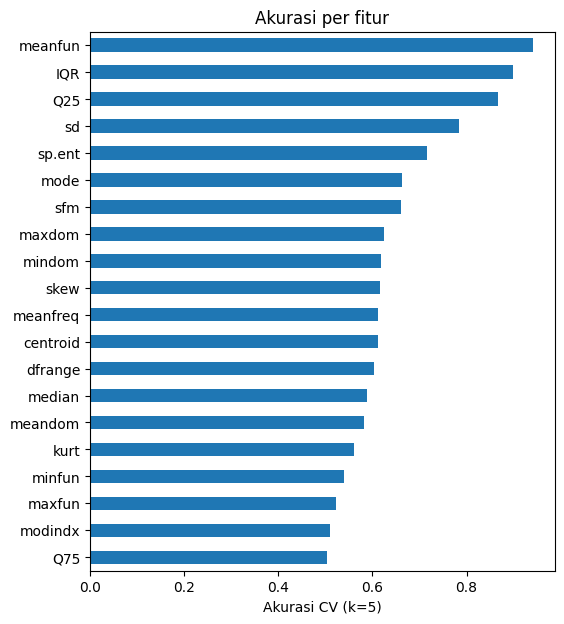

In [ ]:
single = {c: cross_val_score(knn(5), X_train[[c]], y_train, cv=cv).mean()
          for c in X.columns}
single = pd.Series(single).sort_values()

single.plot(kind='barh', figsize=(6, 7))
plt.xlabel('Akurasi CV (k=5)')
plt.title('Akurasi per fitur')
plt.show()

Fitur terbaik: ['meanfun', 'IQR', 'sfm', 'mode', 'skew']


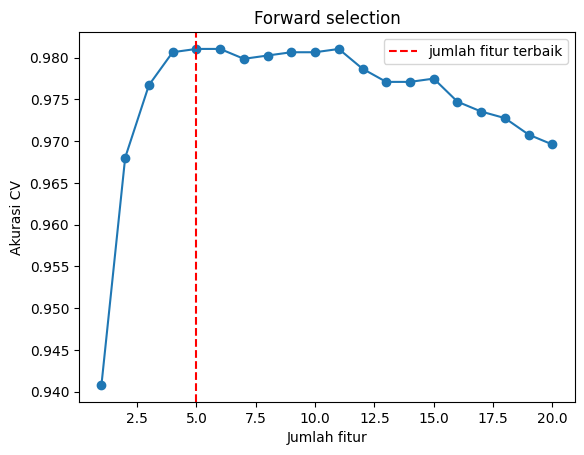

In [ ]:
selected, remaining, history = [], list(X.columns), []
while remaining:
    scores = {c: cross_val_score(knn(5), X_train[selected + [c]], y_train, cv=cv).mean()
              for c in remaining}
    best = max(scores, key=scores.get)
    selected.append(best)
    remaining.remove(best)
    history.append((list(selected), scores[best]))

best_i = max(range(len(history)), key=lambda i: history[i][1])
best_feats = history[best_i][0]
print('Fitur terbaik:', best_feats)

plt.plot(range(1, len(history) + 1), [h[1] for h in history], marker='o')
plt.axvline(best_i + 1, color='red', linestyle='--', label='jumlah fitur terbaik')
plt.xlabel('Jumlah fitur')
plt.ylabel('Akurasi CV')
plt.title('Forward selection')
plt.legend()
plt.show()

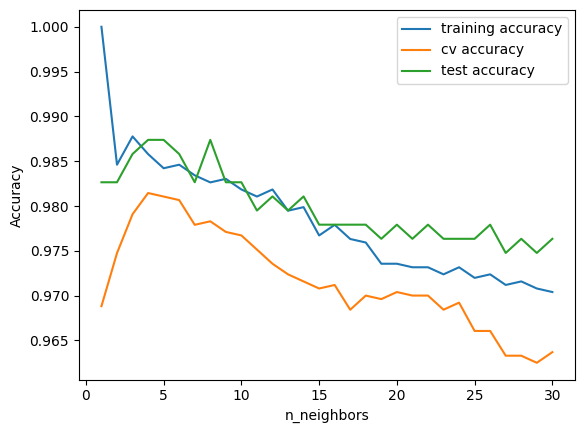

k terbaik (CV): 4


In [ ]:
ks = range(1, 31)
train_acc, cv_acc, test_acc = [], [], []
for k in ks:
    m = knn(k).fit(X_train[best_feats], y_train)
    train_acc.append(m.score(X_train[best_feats], y_train))
    cv_acc.append(cross_val_score(knn(k), X_train[best_feats], y_train, cv=cv).mean())
    test_acc.append(m.score(X_test[best_feats], y_test))

plt.plot(ks, train_acc, label='training accuracy')
plt.plot(ks, cv_acc, label='cv accuracy')
plt.plot(ks, test_acc, label='test accuracy')
plt.xlabel('n_neighbors')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

print('k terbaik (CV):', list(ks)[cv_acc.index(max(cv_acc))])

# Analisis penentuan nilai K terbaik

Penentuan nilai (k) terbaik dilakukan dengan menguji nilai (k) dari 1 hingga 30 pada model k-Nearest Neighbors (kNN), menggunakan lima fitur terpilih, yaitu meanfun, IQR, sfm, mode, dan skew. Evaluasi dilakukan menggunakan 5-fold cross-validation untuk memperoleh rata-rata akurasi pada setiap nilai (k). Selain itu, akurasi data training dan data testing juga dibandingkan untuk mengamati kinerja model.

Berdasarkan hasil percobaan, diperoleh nilai (k) terbaik sebesar 4, yaitu nilai yang menghasilkan akurasi cross-validation tertinggi di antara nilai (k) yang diuji. Nilai tersebut dipilih karena memberikan performa terbaik berdasarkan hasil validasi silang pada data training.

Grafik perbandingan akurasi training, cross-validation, dan testing digunakan untuk mengamati pengaruh jumlah tetangga terhadap kinerja model. Dengan demikian, pemilihan nilai (k) didasarkan pada hasil evaluasi menggunakan cross-validation, bukan ditentukan secara sembarang.